# 04. Calibration by horizon

**Question.** Are prices 24 hours, 6 hours and 1 hour before tipoff as accurate and as well calibrated as the price at tipoff?

**Plan.** This notebook follows `ANALYSIS_PLAN.md` section 9.2, which was committed before any result here was computed. All tests are two-sided at the 0.05 level.

**Data.** `data/processed/snapshots.csv`, main sample, all four horizons. Price `p_home`, outcome `home_win`.

**Seed.** The bootstrap uses seed 4981 and 2,000 replicates, as in the plan.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
from IPython.display import display

from csv_io import write_csv
from horizons import (RESULTS_DIR, bootstrap_table, brier_diff_table, brier_figure,
                      calibration_figure, complete_games, horizon_calibration_bins,
                      horizon_metrics, main_sample_rows, paired_brier_bootstrap,
                      price_source_counts, sample_counts, spread_filter)
from stats_tools import B, SEED

RESULTS_DIR.mkdir(exist_ok=True)
print(f"Bootstrap: B = {B:,}, seed = {SEED}")

Bootstrap: B = 2,000, seed = 4981


## 1. Sample

The comparison uses only games that have a price at all four horizons, so every horizon is scored on the same games.

In [2]:
sn = main_sample_rows()
d = complete_games(sn)
counts = sample_counts(sn, d)
sources = price_source_counts(d)
write_csv(counts, RESULTS_DIR / "horizons_sample_counts.csv")
write_csv(sources, RESULTS_DIR / "horizons_price_source.csv")
display(counts)
display(sources)

,group,games
0,main sample,1229
1,p_home present at 24h,1222
2,p_home present at 6h,1229
3,p_home present at 1h,1229
4,p_home present at tipoff,1229
5,p_home present at all four horizons,1222


,horizon_h,mid
0,24,1222
1,6,1222
2,1,1222
3,0,1222


1,222 of the 1,229 main-sample games have a price at all four horizons. The 7 dropped games have no 24h price. That count matches the 7 games Kalshi listed less than 24 hours before tipoff (see the README). They are dropped from every horizon.

Every one of the 4,888 prices used comes from the bid/ask midpoint. No backup price (last trade or VWAP) is needed in this sample.

## 2. Brier score, recalibration and LR test at each horizon

One row per horizon, computed as in notebook 02: the Brier score with its constant baseline, the intercept a and slope b of the logistic recalibration with standard errors clustered by home team (p values for a = 0 and b = 1), and the likelihood ratio test of a = 0 and b = 1 together.

In [3]:
MAIN = "all four horizons"
metrics = horizon_metrics(d, MAIN)
display(metrics.round(4))

,sample,horizon_h,n,home_win_rate,brier,brier_baseline,brier_diff,brier_skill,intercept_a,a_se_cluster,a_p_value,slope_b,b_se_cluster,b_p_value,lr_stat,lr_p_value
0,all four horizons,24,1222,0.5548,0.1988,0.247,-0.0482,0.1953,0.0332,0.0456,0.4655,1.0323,0.0658,0.6240,0.5502,0.7595
1,all four horizons,6,1222,0.5548,0.1960,0.247,-0.0510,0.2064,0.0155,0.0453,0.7326,1.0134,0.0621,0.8291,0.1110,0.9460
2,all four horizons,1,1222,0.5548,0.1947,0.247,-0.0523,0.2116,0.0127,0.0449,0.7769,1.0298,0.0616,0.6281,0.2512,0.8820
3,all four horizons,0,1222,0.5548,0.1944,0.247,-0.0526,0.2129,0.0162,0.0452,0.7205,1.0344,0.0621,0.5801,0.3458,0.8412


The Brier score falls as tipoff gets closer: 0.1988 at 24h, 0.1960 at 6h, 0.1947 at 1h and 0.1944 at tipoff. The baseline is 0.2470 at every horizon, because the games are the same, so the skill score rises from 0.195 to 0.213. Section 3 tests whether these differences are larger than chance.

On calibration the four horizons look alike. The intercept a is between 0.013 and 0.033, and the slope b is between 1.013 and 1.034. No test of a = 0 or b = 1 rejects (the smallest p value is 0.47), and no LR test rejects (p values from 0.76 to 0.95). At no horizon do the planned tests reject calibration.

## 3. Is the tipoff price more accurate? Paired bootstrap

Each bootstrap replicate draws whole game dates and scores all four horizons on the same resampled games. The table gives the Brier score of each earlier horizon minus the Brier score at tipoff. A positive difference means the earlier price is less accurate.

In [4]:
boot = paired_brier_bootstrap(d)
summary = bootstrap_table(d, boot, MAIN)
diff = brier_diff_table(summary)
display(diff.round(5))
display(summary.round(5))

,sample,horizon_h,brier_h,brier_0h,brier_diff,boot_lo,boot_hi,interval_excludes_0
0,all four horizons,24,0.19876,0.19441,0.00436,0.00162,0.00712,1
1,all four horizons,6,0.19603,0.19441,0.00162,-0.00010,0.00341,0
2,all four horizons,1,0.19472,0.19441,0.00031,-0.00058,0.00125,0


,sample,statistic,estimate,boot_mean,boot_se,boot_lo,boot_hi,B,n_dates,seed
0,all four horizons,brier_24h,0.19876,0.19851,0.00528,0.18858,0.20930,2000,163,4981
1,all four horizons,brier_6h,0.19603,0.19577,0.00533,0.18569,0.20625,2000,163,4981
2,all four horizons,brier_1h,0.19472,0.19447,0.00540,0.18417,0.20512,2000,163,4981
3,all four horizons,brier_0h,0.19441,0.19415,0.00544,0.18383,0.20477,2000,163,4981
4,all four horizons,brier_diff_24h_minus_0h,0.00436,0.00436,0.00140,0.00162,0.00712,2000,163,4981
5,all four horizons,brier_diff_6h_minus_0h,0.00162,0.00162,0.00089,-0.00010,0.00341,2000,163,4981
6,all four horizons,brier_diff_1h_minus_0h,0.00031,0.00032,0.00047,-0.00058,0.00125,2000,163,4981


- **24h against tipoff.** The 24h Brier score is higher by 0.0044, with interval 0.0016 to 0.0071. The interval excludes 0, so the 24h price is less accurate than the tipoff price.
- **6h against tipoff.** Higher by 0.0016, with interval -0.0001 to 0.0034. The interval contains 0, by a small margin.
- **1h against tipoff.** Higher by 0.0003, with interval -0.0006 to 0.0012. The interval contains 0.

The differences are small next to the Brier score itself: 0.0044 is about 2% of 0.194.

This sample has 163 game dates, one fewer than notebook 02, because of the 7 dropped games.

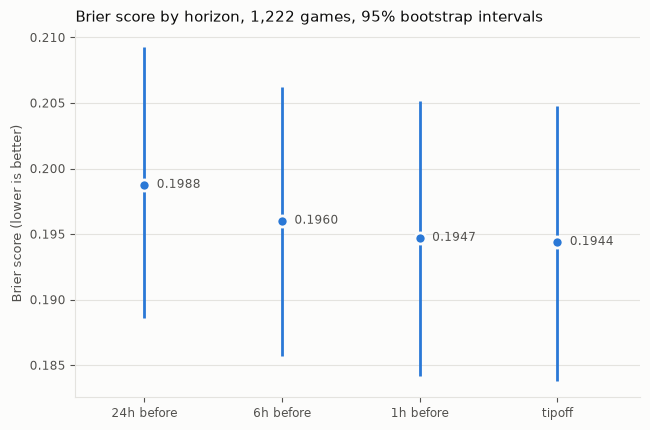

In [5]:
fig = brier_figure(summary, d["game_id"].nunique(), RESULTS_DIR / "horizons_brier.png")

The intervals of the four Brier scores overlap almost completely. That does not contradict section 3. Each interval here shows how much a Brier score changes from one sample of dates to another, and all four horizons share that change because they are scored on the same games. The paired differences in section 3 remove the shared part, which is why they are much tighter.

## 4. Calibration curves

Each horizon gets its own 10 equal-count bins, built from that horizon's prices as in notebook 02. The plot joins the bin points and leaves out the error bars to stay readable. The Wilson intervals are in the table and in `horizons_calibration_bins.csv`.

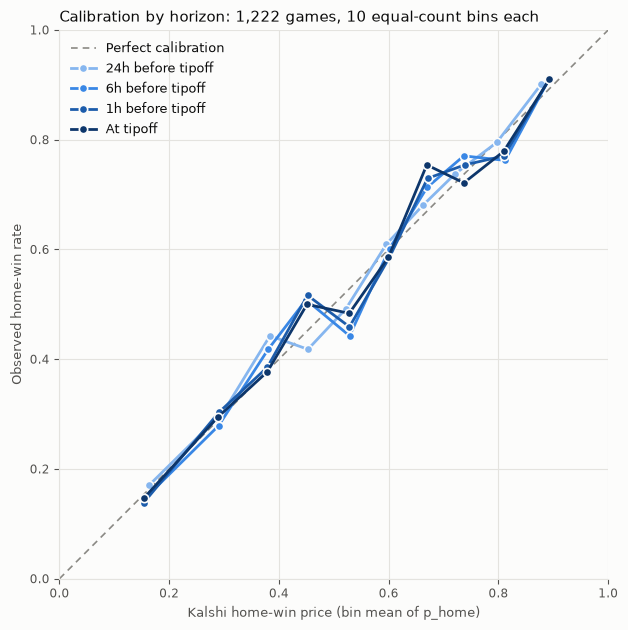

In [6]:
bins = horizon_calibration_bins(d)
write_csv(bins, RESULTS_DIR / "horizons_calibration_bins.csv")
fig = calibration_figure(bins, d["game_id"].nunique(), RESULTS_DIR / "horizons_calibration.png")

In [7]:
display(bins.round(4))

,horizon_h,bin,n,p_min,p_max,mean_p,home_wins,win_rate,wilson_lo,wilson_hi
0,24,1,123,0.0545,0.2362,0.1637,21,0.1707,0.1145,0.2469
1,24,2,122,0.2362,0.3433,0.2982,37,0.3033,0.2287,0.3898
2,24,3,122,0.3434,0.4158,0.3836,54,0.4426,0.3576,0.5312
3,24,4,122,0.4167,0.4874,0.4528,51,0.4180,0.3343,0.5067
4,24,5,122,0.4874,0.5594,0.5219,60,0.4918,0.4047,0.5794
5,24,6,123,0.5594,0.6324,0.5959,75,0.6098,0.5215,0.6914
6,24,7,122,0.6324,0.6950,0.6621,83,0.6803,0.5932,0.7565
7,24,8,122,0.6950,0.7512,0.7210,90,0.7377,0.6533,0.8076
8,24,9,122,0.7512,0.8308,0.7970,97,0.7951,0.7150,0.8572
9,24,10,122,0.8317,0.9550,0.8783,110,0.9016,0.8359,0.9428


The four curves stay close to the 45° line and to each other. In 39 of the 40 bins, the mean price lies inside the Wilson interval of the win rate. The exception is bin 7 at tipoff: mean price 0.669, win rate 0.754, interval 0.671 to 0.822. In notebook 02 the same bin, on 1,229 games, had its mean price just inside the interval.

With 40 intervals at the 95% level, one or two misses are expected even if the prices are perfectly calibrated.

## 5. Robustness: tight spreads only

A wide bid/ask spread makes the midpoint less reliable. This repeats sections 2 and 3 after dropping every game whose `max_spread` is above 0.05, or missing, at any horizon. All horizons still use the same games.

In [8]:
TIGHT = "max_spread <= 0.05 at every horizon"
tight = spread_filter(d)
print(f"{tight['game_id'].nunique():,} of {d['game_id'].nunique():,} games kept, "
      f"{d['game_id'].nunique() - tight['game_id'].nunique()} dropped")
metrics_tight = horizon_metrics(tight, TIGHT)
summary_tight = bootstrap_table(tight, paired_brier_bootstrap(tight), TIGHT)
diff_tight = brier_diff_table(summary_tight)
display(metrics_tight.round(4))
display(diff_tight.round(5))

1,165 of 1,222 games kept, 57 dropped


,sample,horizon_h,n,home_win_rate,brier,brier_baseline,brier_diff,brier_skill,intercept_a,a_se_cluster,a_p_value,slope_b,b_se_cluster,b_p_value,lr_stat,lr_p_value
0,max_spread <= 0.05 at every horizon,24,1165,0.5554,0.1967,0.2469,-0.0503,0.2036,0.0241,0.0472,0.6093,1.0471,0.0668,0.4805,0.6316,0.7292
1,max_spread <= 0.05 at every horizon,6,1165,0.5554,0.1945,0.2469,-0.0524,0.2122,0.0099,0.0475,0.8347,1.0185,0.0637,0.7717,0.1054,0.9487
2,max_spread <= 0.05 at every horizon,1,1165,0.5554,0.1932,0.2469,-0.0537,0.2176,0.0057,0.0477,0.9043,1.0355,0.0631,0.5740,0.2731,0.8724
3,max_spread <= 0.05 at every horizon,0,1165,0.5554,0.1926,0.2469,-0.0543,0.2199,0.0075,0.0481,0.8761,1.0435,0.0633,0.4920,0.4107,0.8143


,sample,horizon_h,brier_h,brier_0h,brier_diff,boot_lo,boot_hi,interval_excludes_0
0,max_spread <= 0.05 at every horizon,24,0.19665,0.19264,0.00401,0.00129,0.00673,1
1,max_spread <= 0.05 at every horizon,6,0.19453,0.19264,0.00189,0.00013,0.00370,1
2,max_spread <= 0.05 at every horizon,1,0.19320,0.19264,0.00056,-0.00034,0.00147,0


The filter drops 57 games and keeps 1,165. The pattern is the same as before. The Brier score is 0.1967 at 24h, 0.1945 at 6h, 0.1932 at 1h and 0.1926 at tipoff, and no calibration test rejects at any horizon (the smallest p value is 0.48).

The paired differences:

- **24h.** +0.0040, interval 0.0013 to 0.0067. It excludes 0, as in the main sample.
- **6h.** +0.0019, interval 0.0001 to 0.0037. It excludes 0 here. In the main sample the interval just contained 0 (-0.0001 to 0.0034).
- **1h.** +0.0006, interval -0.0003 to 0.0015. It contains 0, as in the main sample.

The 24h and 1h conclusions do not depend on the spread filter. The 6h conclusion does: its interval sits at the edge of 0 in both samples and falls on different sides.

In [9]:
write_csv(pd.concat([metrics, metrics_tight], ignore_index=True),
          RESULTS_DIR / "horizons_metrics.csv")
write_csv(pd.concat([diff, diff_tight], ignore_index=True),
          RESULTS_DIR / "horizons_brier_diff.csv")
write_csv(pd.concat([summary, summary_tight], ignore_index=True),
          RESULTS_DIR / "horizons_bootstrap.csv")

**What the numbers show.** By the planned tests, prices are equally well calibrated at all four horizons. Accuracy improves toward tipoff. The 24h price is measurably less accurate than the tipoff price, by about 0.004 in Brier score, in both samples. The 1h price is not distinguishable from the tipoff price. The 6h result is borderline and changes with the spread filter.